In [2]:
# ============================================================
# 1. IMPORTAÇÃO DAS BIBLIOTECAS
# ============================================================

# Biblioteca utilizada para manipulação e análise dos dados
import pandas as pd

# Biblioteca utilizada para operações matemáticas e numéricas
import numpy as np


# ============================================================
# 2. DEFINIÇÃO DO CAMINHO DOS ARQUIVOS
# ============================================================

# Caminho da pasta que contém os arquivos preparados
# pelo processo de pré-processamento
caminho_resultados = "../data_priscila/wq/etapa_3/resultados/"


# ============================================================
# 3. CARREGAMENTO DOS DADOS
# ============================================================

# Carrega as variáveis preditoras do conjunto de treinamento
X_train = pd.read_csv(caminho_resultados + "X_train.csv")

# Carrega as variáveis preditoras do conjunto de teste
X_test = pd.read_csv(caminho_resultados + "X_test.csv")

# Carrega a variável alvo do conjunto de treinamento
y_train = pd.read_csv(caminho_resultados + "y_train.csv").squeeze()

# Carrega a variável alvo do conjunto de teste
y_test = pd.read_csv(caminho_resultados + "y_test.csv").squeeze()


# ============================================================
# 4. VERIFICAÇÃO DA ESTRUTURA DOS DADOS
# ============================================================

# Exibe a quantidade de registros e variáveis de cada conjunto
print("DIMENSÕES DOS CONJUNTOS DE DADOS")
print("-" * 45)

print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test:  {y_test.shape}")

DIMENSÕES DOS CONJUNTOS DE DADOS
---------------------------------------------
X_train: (814, 11)
X_test:  (204, 11)
y_train: (814,)
y_test:  (204,)


In [2]:
# ============================================================
# 5. ANÁLISE DA DISTRIBUIÇÃO DA VARIÁVEL-ALVO
# ============================================================

# Objetivo:
# Verificar a quantidade e a proporção de registros
# pertencentes a cada classe nos conjuntos de treino e teste.


# ------------------------------------------------------------
# 5.1 Distribuição das classes no conjunto de treinamento
# ------------------------------------------------------------

print("DISTRIBUIÇÃO DAS CLASSES - TREINAMENTO")
print("-" * 50)

# Conta a quantidade de registros de cada classe
print(y_train.value_counts().sort_index())

# Calcula a proporção percentual de cada classe
print("\nProporção percentual:")
print((y_train.value_counts(normalize=True).sort_index() * 100).round(2))


# ------------------------------------------------------------
# 5.2 Distribuição das classes no conjunto de teste
# ------------------------------------------------------------

print("\nDISTRIBUIÇÃO DAS CLASSES - TESTE")
print("-" * 50)

# Conta a quantidade de registros de cada classe
print(y_test.value_counts().sort_index())

# Calcula a proporção percentual de cada classe
print("\nProporção percentual:")
print((y_test.value_counts(normalize=True).sort_index() * 100).round(2))

DISTRIBUIÇÃO DAS CLASSES - TREINAMENTO
--------------------------------------------------
quality_class
0    704
1    110
Name: count, dtype: int64

Proporção percentual:
quality_class
0    86.49
1    13.51
Name: proportion, dtype: float64

DISTRIBUIÇÃO DAS CLASSES - TESTE
--------------------------------------------------
quality_class
0    177
1     27
Name: count, dtype: int64

Proporção percentual:
quality_class
0    86.76
1    13.24
Name: proportion, dtype: float64


### Análise da distribuição da variável-alvo

A distribuição das classes demonstra um desequilíbrio na variável-alvo `quality_class`.

No conjunto de treinamento, 86,49% dos registros pertencem à classe 0 e 13,51% à classe 1. No conjunto de teste, as proporções são de 86,76% e 13,24%, respectivamente.

Observa-se que a divisão entre treinamento e teste preservou adequadamente a distribuição das classes.

Devido ao desequilíbrio identificado, a avaliação do modelo não deverá considerar apenas a acurácia. Serão utilizadas também métricas como precisão, recall e F1-score, além da matriz de confusão, com atenção especial à identificação dos vinhos pertencentes à classe 1.

In [3]:
# ============================================================
# 6. VERIFICAÇÃO DA QUALIDADE DOS DADOS
# ============================================================

# Objetivo:
# Verificar os tipos das variáveis e identificar possíveis
# valores ausentes nos conjuntos de treinamento e teste.


# ------------------------------------------------------------
# 6.1 Verificação dos tipos das variáveis
# ------------------------------------------------------------

print("TIPOS DAS VARIÁVEIS")
print("-" * 50)

# Exibe o tipo de dado de cada variável preditora
print(X_train.dtypes)


# ------------------------------------------------------------
# 6.2 Verificação de valores ausentes
# ------------------------------------------------------------

print("\nVALORES AUSENTES - TREINAMENTO")
print("-" * 50)

# Conta a quantidade de valores ausentes por variável
print(X_train.isnull().sum())


print("\nVALORES AUSENTES - TESTE")
print("-" * 50)

# Conta a quantidade de valores ausentes por variável
print(X_test.isnull().sum())


# ------------------------------------------------------------
# 6.3 Verificação de valores ausentes na variável-alvo
# ------------------------------------------------------------

print("\nVALORES AUSENTES - VARIÁVEL-ALVO")
print("-" * 50)

print("y_train:", y_train.isnull().sum())
print("y_test:", y_test.isnull().sum())


TIPOS DAS VARIÁVEIS
--------------------------------------------------
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
dtype: object

VALORES AUSENTES - TREINAMENTO
--------------------------------------------------
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
dtype: int64

VALORES AUSENTES - TESTE
--------------------------------------------------
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0


In [4]:
# ============================================================
# 7. RESUMO DA VERIFICAÇÃO DE VALORES AUSENTES
# ============================================================

# Objetivo:
# Apresentar um resumo da quantidade de valores ausentes
# em cada conjunto de dados.

print("RESUMO DE VALORES AUSENTES")
print("-" * 50)

print(f"X_train: {X_train.isnull().sum().sum()} valores ausentes")
print(f"X_test:  {X_test.isnull().sum().sum()} valores ausentes")
print(f"y_train: {y_train.isnull().sum()} valores ausentes")
print(f"y_test:  {y_test.isnull().sum()} valores ausentes")

RESUMO DE VALORES AUSENTES
--------------------------------------------------
X_train: 0 valores ausentes
X_test:  0 valores ausentes
y_train: 0 valores ausentes
y_test:  0 valores ausentes


In [5]:
# ============================================================
# 8. CONSTRUÇÃO DO MODELO DE REGRESSÃO LOGÍSTICA
# ============================================================

# Objetivo:
# Criar um pipeline que combina o escalonamento das variáveis
# com o treinamento do classificador de regressão logística.


# ------------------------------------------------------------
# 8.1 Importação das bibliotecas de modelagem
# ------------------------------------------------------------

# RobustScaler realiza o escalonamento utilizando mediana
# e intervalo interquartil, reduzindo a influência de outliers.

from sklearn.preprocessing import RobustScaler

# LogisticRegression é o algoritmo de classificação
# que será utilizado para prever a qualidade dos vinhos.

from sklearn.linear_model import LogisticRegression

# Pipeline organiza as etapas de transformação e modelagem
# em uma única estrutura.

from sklearn.pipeline import Pipeline


# ------------------------------------------------------------
# 8.2 Criação do pipeline
# ------------------------------------------------------------

# O pipeline executa duas etapas:
# 1. Escalonamento das variáveis com RobustScaler.
# 2. Treinamento do modelo de regressão logística.

modelo_logistico = Pipeline(steps=[
    ("escalonamento", RobustScaler()),
    ("classificador", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])


# ------------------------------------------------------------
# 8.3 Treinamento do modelo
# ------------------------------------------------------------

# O modelo aprende os padrões das variáveis preditoras
# utilizando exclusivamente os dados de treinamento.

modelo_logistico.fit(X_train, y_train)


# ------------------------------------------------------------
# 8.4 Confirmação do treinamento
# ------------------------------------------------------------

print("MODELO DE REGRESSÃO LOGÍSTICA")
print("-" * 50)

print("Treinamento concluído com sucesso!")
print(f"Algoritmo: {modelo_logistico.named_steps['classificador']}")


MODELO DE REGRESSÃO LOGÍSTICA
--------------------------------------------------
Treinamento concluído com sucesso!
Algoritmo: LogisticRegression(max_iter=1000, random_state=42)


In [6]:
# ============================================================
# 9. AVALIAÇÃO INICIAL DO MODELO
# ============================================================

# Objetivo:
# Avaliar o desempenho da regressão logística utilizando
# os dados de teste, que não participaram do treinamento.


# ------------------------------------------------------------
# 9.1 Importação das métricas de avaliação
# ------------------------------------------------------------

# Métricas utilizadas para avaliar modelos de classificação
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)


# ------------------------------------------------------------
# 9.2 Realização das previsões
# ------------------------------------------------------------

# Utiliza o modelo treinado para prever a classe dos vinhos
# presentes no conjunto de teste.

y_pred = modelo_logistico.predict(X_test)


# ------------------------------------------------------------
# 9.3 Cálculo das métricas de desempenho
# ------------------------------------------------------------

# Acurácia: proporção total de previsões corretas.
acuracia = accuracy_score(y_test, y_pred)

# Precisão: proporção de previsões positivas que estavam corretas.
precisao = precision_score(y_test, y_pred, zero_division=0)

# Recall: proporção dos casos positivos reais identificados.
recall = recall_score(y_test, y_pred, zero_division=0)

# F1-score: equilíbrio entre precisão e recall.
f1 = f1_score(y_test, y_pred, zero_division=0)


# ------------------------------------------------------------
# 9.4 Exibição dos resultados
# ------------------------------------------------------------

print("AVALIAÇÃO INICIAL DA REGRESSÃO LOGÍSTICA")
print("-" * 55)

print(f"Acurácia:  {acuracia:.4f}")
print(f"Precisão:  {precisao:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")


# ------------------------------------------------------------
# 9.5 Relatório completo de classificação
# ------------------------------------------------------------

# Apresenta as métricas separadamente para cada classe.
print("\nRELATÓRIO DE CLASSIFICAÇÃO")
print("-" * 55)

print(classification_report(
    y_test,
    y_pred,
    target_names=[
        "Classe 0 - Qualidade abaixo de 7",
        "Classe 1 - Qualidade igual ou acima de 7"
    ],
    zero_division=0
))

AVALIAÇÃO INICIAL DA REGRESSÃO LOGÍSTICA
-------------------------------------------------------
Acurácia:  0.8971
Precisão:  0.6500
Recall:    0.4815
F1-score:  0.5532

RELATÓRIO DE CLASSIFICAÇÃO
-------------------------------------------------------
                                          precision    recall  f1-score   support

        Classe 0 - Qualidade abaixo de 7       0.92      0.96      0.94       177
Classe 1 - Qualidade igual ou acima de 7       0.65      0.48      0.55        27

                                accuracy                           0.90       204
                               macro avg       0.79      0.72      0.75       204
                            weighted avg       0.89      0.90      0.89       204



### Avaliação inicial da regressão logística

O modelo inicial de regressão logística apresentou acurácia de 89,71% no conjunto de teste.

Entretanto, a análise das métricas por classe demonstra diferenças importantes no desempenho da classificação.

Para a classe 0 (qualidade abaixo de 7), o modelo apresentou precisão de 92%, recall de 96% e F1-score de 94%, indicando bom desempenho na identificação desses registros.

Para a classe 1 (qualidade igual ou superior a 7), foram obtidos precisão de 65%, recall de 48,15% e F1-score de 55,32%.

O resultado demonstra que, apesar da boa acurácia geral, o modelo apresenta dificuldade para identificar os vinhos pertencentes à classe minoritária.

Esse comportamento pode estar relacionado ao desequilíbrio identificado anteriormente na variável-alvo, em que aproximadamente 86% dos registros pertencem à classe 0.

Dessa forma, a acurácia isoladamente não é suficiente para avaliar a qualidade do modelo. Será necessário investigar estratégias para melhorar a identificação da classe 1, considerando principalmente o recall e o F1-score.

MATRIZ DE CONFUSÃO
--------------------------------------------------
[[170   7]
 [ 14  13]]


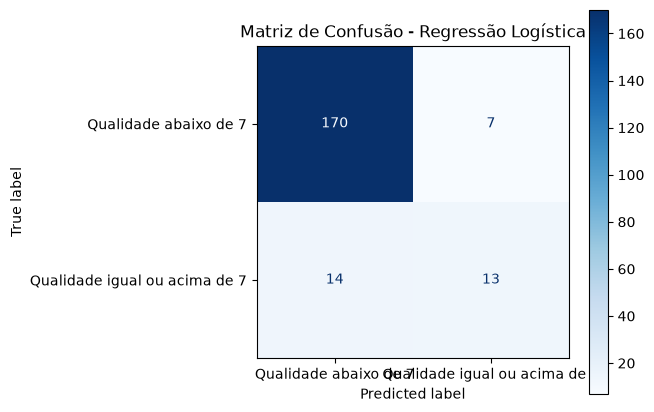

In [7]:
# ============================================================
# 10. MATRIZ DE CONFUSÃO
# ============================================================

# Objetivo:
# Avaliar os acertos e erros do modelo de regressão logística
# em cada uma das duas classes de qualidade dos vinhos.


# ------------------------------------------------------------
# 10.1 Importação das bibliotecas
# ------------------------------------------------------------

# confusion_matrix calcula a matriz de confusão.
# ConfusionMatrixDisplay permite apresentar a matriz graficamente.

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 10.2 Cálculo da matriz de confusão
# ------------------------------------------------------------

# Compara as classes reais (y_test) com as classes previstas
# pelo modelo (y_pred).

matriz_confusao = confusion_matrix(y_test, y_pred)


# ------------------------------------------------------------
# 10.3 Exibição dos valores da matriz
# ------------------------------------------------------------

print("MATRIZ DE CONFUSÃO")
print("-" * 50)

print(matriz_confusao)


# ------------------------------------------------------------
# 10.4 Visualização gráfica da matriz
# ------------------------------------------------------------

# Apresenta a quantidade de classificações corretas
# e incorretas para cada classe.

visualizacao = ConfusionMatrixDisplay(
    confusion_matrix=matriz_confusao,
    display_labels=[
        "Qualidade abaixo de 7",
        "Qualidade igual ou acima de 7"
    ]
)

# Cria o gráfico da matriz de confusão
visualizacao.plot(cmap="Blues", values_format="d")

# Define o título do gráfico
plt.title("Matriz de Confusão - Regressão Logística")

# Ajusta o layout para melhorar a leitura
plt.tight_layout()

# Exibe o gráfico
plt.show()

### Análise da matriz de confusão

A matriz de confusão da regressão logística apresentou 170 verdadeiros negativos, 7 falsos positivos, 14 falsos negativos e 13 verdadeiros positivos.

Observa-se que o modelo apresenta bom desempenho na identificação dos vinhos pertencentes à classe 0 (qualidade abaixo de 7), classificando corretamente 170 dos 177 registros dessa categoria.

Entretanto, para a classe 1 (qualidade igual ou superior a 7), o modelo identificou corretamente apenas 13 dos 27 registros, enquanto 14 foram classificados incorretamente como classe 0.

Esse resultado evidencia uma dificuldade na identificação da classe minoritária, reforçando a necessidade de investigar estratégias para melhorar o desempenho do modelo nessa categoria.

A análise também confirma que a acurácia geral, isoladamente, não representa adequadamente o desempenho da classificação, sendo importante considerar as métricas individuais de cada classe.

In [8]:
# ============================================================
# 11. ANÁLISE DOS ERROS DE CLASSIFICAÇÃO
# ============================================================

# Objetivo:
# Identificar os vinhos que foram classificados incorretamente
# pelo modelo de regressão logística e analisar suas características.


# ------------------------------------------------------------
# 11.1 Criação de uma tabela de análise
# ------------------------------------------------------------

# Cria uma cópia das variáveis do conjunto de teste.
# As alterações serão realizadas somente nessa nova tabela.

analise_erros = X_test.copy()


# ------------------------------------------------------------
# 11.2 Inclusão das classes reais e previstas
# ------------------------------------------------------------

# Adiciona a classe verdadeira de cada vinho.

analise_erros["classe_real"] = y_test.to_numpy()

# Adiciona a classe prevista pelo modelo.

analise_erros["classe_prevista"] = y_pred


# ------------------------------------------------------------
# 11.3 Identificação dos registros classificados incorretamente
# ------------------------------------------------------------

# Seleciona somente os registros em que a previsão
# foi diferente da classe real.

erros_classificacao = analise_erros[
    analise_erros["classe_real"] != analise_erros["classe_prevista"]
].copy()


# ------------------------------------------------------------
# 11.4 Separação dos tipos de erro
# ------------------------------------------------------------

# Falsos positivos: vinhos da classe 0 previstos como classe 1.

falsos_positivos = erros_classificacao[
    (erros_classificacao["classe_real"] == 0) &
    (erros_classificacao["classe_prevista"] == 1)
]

# Falsos negativos: vinhos da classe 1 previstos como classe 0.

falsos_negativos = erros_classificacao[
    (erros_classificacao["classe_real"] == 1) &
    (erros_classificacao["classe_prevista"] == 0)
]


# ------------------------------------------------------------
# 11.5 Apresentação dos resultados
# ------------------------------------------------------------

print("RESUMO DOS ERROS DE CLASSIFICAÇÃO")
print("-" * 55)

print(f"Total de erros: {len(erros_classificacao)}")
print(f"Falsos positivos: {len(falsos_positivos)}")
print(f"Falsos negativos: {len(falsos_negativos)}")


# ------------------------------------------------------------
# 11.6 Visualização dos registros com erros
# ------------------------------------------------------------

# Exibe as características dos vinhos classificados incorretamente.

print("\nREGISTROS CLASSIFICADOS INCORRETAMENTE")
print("-" * 55)

display(erros_classificacao)

RESUMO DOS ERROS DE CLASSIFICAÇÃO
-------------------------------------------------------
Total de erros: 21
Falsos positivos: 7
Falsos negativos: 14

REGISTROS CLASSIFICADOS INCORRETAMENTE
-------------------------------------------------------


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,classe_real,classe_prevista
6,7.9,0.650,0.01,2.50,0.078,17.0,38.0,0.99630,3.34,0.74,11.70,1,0
14,6.1,0.400,0.16,1.80,0.069,11.0,25.0,0.99550,3.42,0.74,10.10,1,0
50,10.3,0.270,0.24,2.10,0.072,15.0,33.0,0.99560,3.22,0.66,12.80,0,1
51,10.1,0.270,0.54,2.30,0.065,7.0,26.0,0.99531,3.17,0.53,12.50,0,1
52,10.4,0.330,0.63,2.80,0.084,5.0,22.0,0.99980,3.26,0.74,11.20,1,0
65,8.5,0.400,0.40,6.30,0.050,3.0,10.0,0.99566,3.28,0.56,12.00,0,1
72,9.6,0.320,0.47,1.40,0.056,9.0,24.0,0.99695,3.22,0.82,10.30,1,0
83,6.6,0.560,0.14,2.40,0.064,13.0,29.0,0.99397,3.42,0.62,11.70,1,0
84,15.9,0.360,0.65,7.50,0.096,22.0,71.0,0.99760,2.98,0.84,14.90,0,1
86,8.9,0.400,0.32,5.60,0.087,10.0,47.0,0.99910,3.38,0.77,10.50,1,0


In [9]:
# ============================================================
# 12. COMPARAÇÃO DAS CARACTERÍSTICAS ENTRE OS GRUPOS
# ============================================================

# Objetivo:
# Comparar as características dos vinhos classificados corretamente
# com aquelas dos vinhos que geraram falsos positivos e falsos negativos.


# ------------------------------------------------------------
# 12.1 Criação de uma cópia para a análise
# ------------------------------------------------------------

# Cria uma cópia do conjunto de teste.
# Dessa forma, os dados originais permanecem preservados.

comparacao_grupos = X_test.copy()


# ------------------------------------------------------------
# 12.2 Inclusão das classes reais e previstas
# ------------------------------------------------------------

# Adiciona a classe verdadeira de cada observação.

comparacao_grupos["classe_real"] = y_test.to_numpy()

# Adiciona a classe prevista pelo modelo.

comparacao_grupos["classe_prevista"] = y_pred


# ------------------------------------------------------------
# 12.3 Identificação do resultado da classificação
# ------------------------------------------------------------

# Define o grupo de cada vinho de acordo com o resultado da previsão.

comparacao_grupos["resultado"] = np.select(
    [
        (comparacao_grupos["classe_real"] == 0) &
        (comparacao_grupos["classe_prevista"] == 1),

        (comparacao_grupos["classe_real"] == 1) &
        (comparacao_grupos["classe_prevista"] == 0)
    ],
    [
        "Falso positivo",
        "Falso negativo"
    ],
    default="Classificação correta"
)


# ------------------------------------------------------------
# 12.4 Quantidade de observações em cada grupo
# ------------------------------------------------------------

print("QUANTIDADE DE VINHOS POR GRUPO")
print("-" * 55)

print(comparacao_grupos["resultado"].value_counts())


# ------------------------------------------------------------
# 12.5 Cálculo das médias das variáveis
# ------------------------------------------------------------

# Agrupa os registros pelo resultado da classificação
# e calcula a média de cada variável numérica.

medias_grupos = comparacao_grupos.groupby("resultado")[
    X_test.columns
].mean().round(3)


# ------------------------------------------------------------
# 12.6 Cálculo das medianas das variáveis
# ------------------------------------------------------------

# Calcula a mediana de cada variável em cada grupo.

medianas_grupos = comparacao_grupos.groupby("resultado")[
    X_test.columns
].median().round(3)


# ------------------------------------------------------------
# 12.7 Apresentação dos resultados
# ------------------------------------------------------------

print("\nMÉDIAS DAS VARIÁVEIS POR GRUPO")
print("-" * 55)

display(medias_grupos.T)


print("\nMEDIANAS DAS VARIÁVEIS POR GRUPO")
print("-" * 55)

display(medianas_grupos.T)

QUANTIDADE DE VINHOS POR GRUPO
-------------------------------------------------------
resultado
Classificação correta    183
Falso negativo            14
Falso positivo             7
Name: count, dtype: int64

MÉDIAS DAS VARIÁVEIS POR GRUPO
-------------------------------------------------------


resultado,Classificação correta,Falso negativo,Falso positivo
fixed acidity,8.014,8.036,11.514
volatile acidity,0.554,0.456,0.385
citric acid,0.229,0.309,0.507
residual sugar,2.637,2.421,6.129
chlorides,0.083,0.075,0.076
free sulfur dioxide,16.391,14.143,9.286
total sulfur dioxide,47.921,43.000,28.857
density,0.997,0.996,0.998
pH,3.324,3.339,3.129
sulphates,0.621,0.729,0.739



MEDIANAS DAS VARIÁVEIS POR GRUPO
-------------------------------------------------------


resultado,Classificação correta,Falso negativo,Falso positivo
fixed acidity,7.600,7.850,10.600
volatile acidity,0.540,0.415,0.360
citric acid,0.210,0.320,0.540
residual sugar,2.200,2.200,6.200
chlorides,0.078,0.070,0.072
free sulfur dioxide,14.000,12.500,6.000
total sulfur dioxide,40.000,28.500,24.000
density,0.997,0.996,0.998
pH,3.330,3.335,3.120
sulphates,0.600,0.740,0.660


### 12.8 Interpretação da comparação entre os grupos

A comparação das médias das variáveis entre os grupos de classificação permitiu identificar diferenças nas características dos vinhos classificados corretamente e daqueles que geraram erros.

Os falsos negativos apresentaram médias superiores de álcool e sulfatos em relação aos vinhos classificados corretamente, além de menor acidez volátil. Essas diferenças indicam que algumas características dos vinhos de qualidade igual ou superior a 7 podem não ter sido suficientemente representadas pelo modelo.

Nos falsos positivos, destacaram-se as médias mais elevadas de álcool, ácido cítrico, acidez fixa e açúcar residual. Esse comportamento sugere que determinadas combinações de características podem levar o modelo a prever a classe de maior qualidade para vinhos cuja classificação real pertence à classe 0.

Os resultados devem ser interpretados com cautela, principalmente porque os grupos de falsos positivos e falsos negativos possuem poucas observações. Portanto, as diferenças identificadas representam indícios exploratórios, e não relações causais ou estatisticamente comprovadas.

A análise reforça a importância de investigar as variáveis preditoras e avaliar outras estratégias de modelagem para melhorar a identificação dos vinhos da classe 1.

In [10]:
# ============================================================
# 13. COMPARAÇÃO DAS VARIÁVEIS ENTRE AS CLASSES
# ============================================================

# Objetivo:
# Identificar diferenças nas características físico-químicas
# dos vinhos pertencentes às classes 0 e 1.


# ------------------------------------------------------------
# 13.1 Criação de uma tabela de análise
# ------------------------------------------------------------

# Cria uma cópia das variáveis do conjunto de treinamento.
# A análise será feita sobre os dados de treinamento,
# preservando o conjunto original.

comparacao_classes = X_train.copy()


# ------------------------------------------------------------
# 13.2 Inclusão da classe real de cada vinho
# ------------------------------------------------------------

# Adiciona a variável alvo ao conjunto de análise.

comparacao_classes["quality_class"] = y_train.to_numpy()


# ------------------------------------------------------------
# 13.3 Cálculo das médias por classe
# ------------------------------------------------------------

# Agrupa os vinhos pela classe de qualidade
# e calcula a média das 11 variáveis.

medias_classes = comparacao_classes.groupby(
    "quality_class"
)[X_train.columns].mean().round(3)


# ------------------------------------------------------------
# 13.4 Cálculo das medianas por classe
# ------------------------------------------------------------

# Calcula a mediana das variáveis para cada classe.

medianas_classes = comparacao_classes.groupby(
    "quality_class"
)[X_train.columns].median().round(3)


# ------------------------------------------------------------
# 13.5 Quantidade de registros por classe
# ------------------------------------------------------------

print("QUANTIDADE DE VINHOS POR CLASSE")
print("-" * 55)

print(comparacao_classes["quality_class"].value_counts().sort_index())


# ------------------------------------------------------------
# 13.6 Apresentação das médias
# ------------------------------------------------------------

print("\nMÉDIAS DAS VARIÁVEIS POR CLASSE")
print("-" * 55)

display(medias_classes.T)


# ------------------------------------------------------------
# 13.7 Apresentação das medianas
# ------------------------------------------------------------

print("\nMEDIANAS DAS VARIÁVEIS POR CLASSE")
print("-" * 55)

display(medianas_classes.T)

QUANTIDADE DE VINHOS POR CLASSE
-------------------------------------------------------
quality_class
0    704
1    110
Name: count, dtype: int64

MÉDIAS DAS VARIÁVEIS POR CLASSE
-------------------------------------------------------


quality_class,0,1
fixed acidity,8.253,8.797
volatile acidity,0.553,0.392
citric acid,0.258,0.387
residual sugar,2.427,2.744
chlorides,0.091,0.074
free sulfur dioxide,15.844,13.764
total sulfur dioxide,47.706,36.373
density,0.997,0.996
pH,3.314,3.283
sulphates,0.650,0.748



MEDIANAS DAS VARIÁVEIS POR CLASSE
-------------------------------------------------------


quality_class,0,1
fixed acidity,7.900,8.600
volatile acidity,0.550,0.360
citric acid,0.240,0.400
residual sugar,2.200,2.250
chlorides,0.080,0.070
free sulfur dioxide,14.000,11.500
total sulfur dioxide,41.000,27.000
density,0.997,0.995
pH,3.310,3.270
sulphates,0.610,0.740


### 13.8 Interpretação da comparação entre as classes

A comparação das estatísticas descritivas revelou diferenças nas características físico-químicas dos vinhos pertencentes às duas classes de qualidade.

A variável `alcohol` apresentou uma das diferenças mais expressivas, com média de 10,266 na classe 0 e 11,582 na classe 1. A variável `volatile acidity` apresentou comportamento inverso, com média de 0,553 na classe 0 e 0,392 na classe 1.

Também foram observadas médias superiores de `sulphates` e `citric acid` nos vinhos da classe 1. Por outro lado, `total sulfur dioxide` e `chlorides` apresentaram médias inferiores nessa classe.

Esses resultados indicam que determinadas características físico-químicas podem ajudar a diferenciar os vinhos de acordo com a classificação de qualidade.

Entretanto, as diferenças observadas nas estatísticas descritivas não comprovam, isoladamente, a importância preditiva das variáveis. Será necessário complementar a análise com visualizações, correlações e avaliações do modelo.

Também foi identificado um desequilíbrio entre as classes: 704 registros pertencem à classe 0 e 110 à classe 1. Essa característica deve ser considerada na interpretação dos resultados e no desenvolvimento dos modelos.

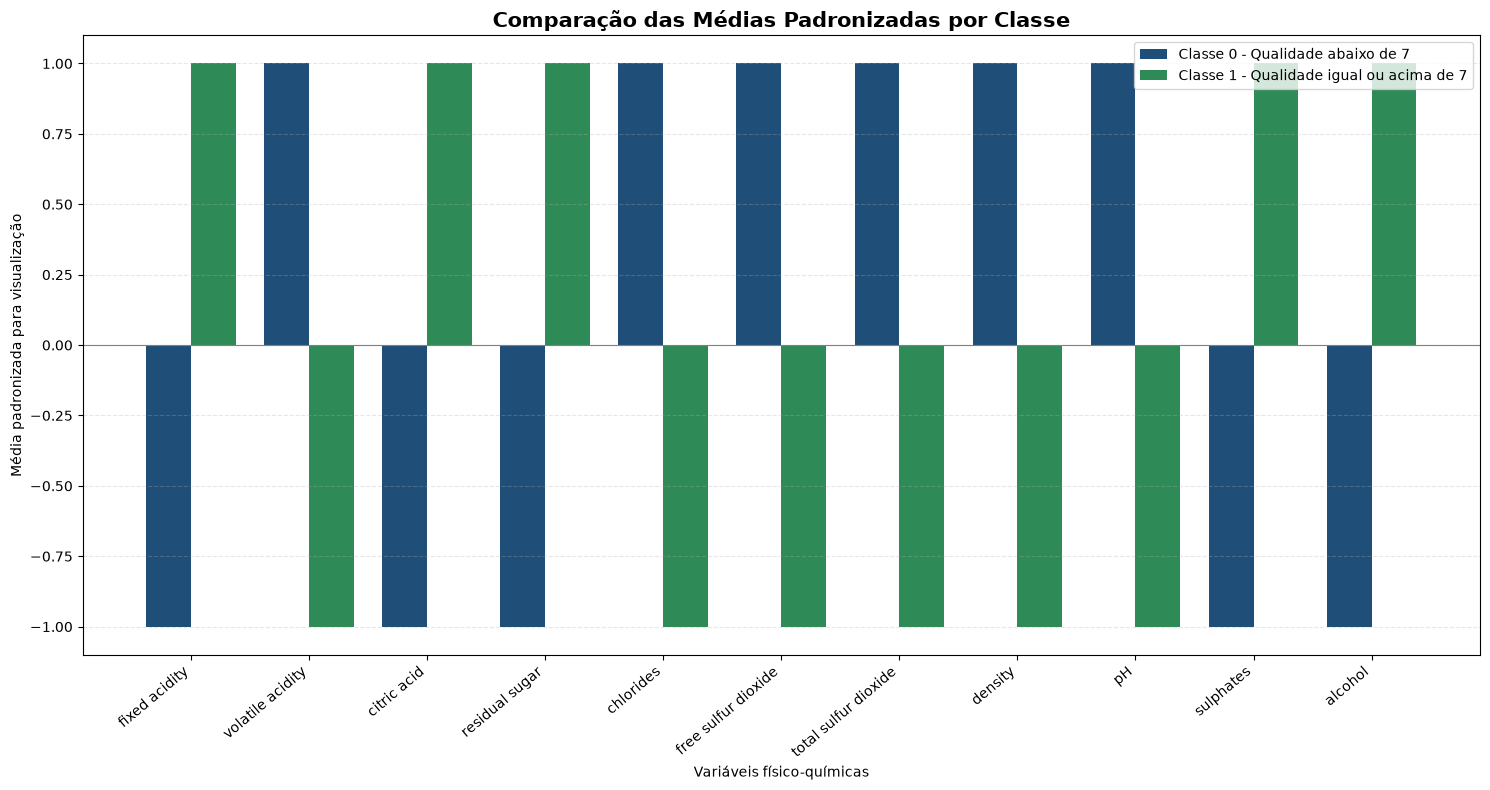

In [12]:
# ============================================================
# 14. COMPARAÇÃO VISUAL DAS VARIÁVEIS ENTRE AS CLASSES
# ============================================================

# Objetivo:
# Comparar as médias padronizadas das 11 variáveis
# entre as classes 0 e 1.


# ------------------------------------------------------------
# 14.1 Preparação das médias
# ------------------------------------------------------------

# Recupera as médias calculadas anteriormente.

medias_grafico = medias_classes.copy()


# ------------------------------------------------------------
# 14.2 Padronização para visualização
# ------------------------------------------------------------

# Calcula a média geral de cada variável.

media_geral = medias_grafico.mean(axis=0)

# Calcula o desvio-padrão entre as médias das duas classes.

desvio_entre_classes = medias_grafico.std(axis=0, ddof=0)

# Padroniza as médias para permitir a comparação visual.

medias_padronizadas = (
    medias_grafico - media_geral
) / desvio_entre_classes.replace(0, np.nan)


# ------------------------------------------------------------
# 14.3 Criação do gráfico
# ------------------------------------------------------------

import matplotlib.pyplot as plt

# Define as 11 variáveis no eixo horizontal.

posicoes = np.arange(len(medias_padronizadas.columns))

# Define a largura das barras.

largura = 0.38

# Cria a figura.

fig, ax = plt.subplots(figsize=(15, 8))

# Barras da classe 0.

ax.bar(
    posicoes - largura / 2,
    medias_padronizadas.loc[0].values,
    largura,
    label="Classe 0 - Qualidade abaixo de 7",
    color="#1F4E78"
)

# Barras da classe 1.

ax.bar(
    posicoes + largura / 2,
    medias_padronizadas.loc[1].values,
    largura,
    label="Classe 1 - Qualidade igual ou acima de 7",
    color="#2E8B57"
)


# ------------------------------------------------------------
# 14.4 Personalização do gráfico
# ------------------------------------------------------------

# Identifica as variáveis no eixo horizontal.

ax.set_xticks(posicoes)

ax.set_xticklabels(
    medias_padronizadas.columns,
    rotation=40,
    ha="right"
)

# Define título e identificação dos eixos.

ax.set_title(
    "Comparação das Médias Padronizadas por Classe",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Variáveis físico-químicas")

ax.set_ylabel("Média padronizada para visualização")

# Adiciona linha de referência e grade.

ax.axhline(0, color="gray", linewidth=0.8)

ax.grid(axis="y", linestyle="--", alpha=0.3)

# Adiciona legenda.

ax.legend()

# Ajusta o espaçamento e apresenta o gráfico.

plt.tight_layout()

plt.show()

In [13]:
# ============================================================
# 15. CONFERÊNCIA DOS DADOS UTILIZADOS NO GRÁFICO
# ============================================================

# Objetivo:
# Verificar os valores utilizados na visualização
# e confirmar se as 11 variáveis foram representadas.

print("DIMENSÕES DA TABELA PADRONIZADA")
print(medias_padronizadas.shape)

print("\nVALORES PADRONIZADOS POR CLASSE")
display(medias_padronizadas.T)

print("\nVERIFICAÇÃO DE VALORES AUSENTES")
print(medias_padronizadas.isnull().sum())

DIMENSÕES DA TABELA PADRONIZADA
(2, 11)

VALORES PADRONIZADOS POR CLASSE


quality_class,0,1
fixed acidity,-1.0,1.0
volatile acidity,1.0,-1.0
citric acid,-1.0,1.0
residual sugar,-1.0,1.0
chlorides,1.0,-1.0
free sulfur dioxide,1.0,-1.0
total sulfur dioxide,1.0,-1.0
density,1.0,-1.0
pH,1.0,-1.0
sulphates,-1.0,1.0



VERIFICAÇÃO DE VALORES AUSENTES
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
dtype: int64


### 14.5 Interpretação da comparação visual das variáveis

A visualização das médias padronizadas permitiu comparar as características físico-químicas dos vinhos pertencentes às classes 0 e 1.

Observou-se que a classe 1 apresentou médias superiores de acidez fixa, ácido cítrico, açúcar residual, sulfatos e álcool. Em contrapartida, apresentou médias inferiores de acidez volátil, cloretos, dióxido de enxofre livre, dióxido de enxofre total, densidade e pH.

O gráfico evidencia diferenças entre os perfis médios das duas classes, complementando a análise das estatísticas descritivas.

A padronização foi utilizada exclusivamente para facilitar a comparação visual, sem modificar os conjuntos de dados originais ou interferir no treinamento do modelo.

As diferenças observadas indicam variáveis que merecem investigação adicional, mas não comprovam isoladamente sua importância preditiva.

In [14]:
    # ============================================================
# 15. CORRELAÇÃO DAS VARIÁVEIS COM A CLASSE DE QUALIDADE
# ============================================================

# Objetivo:
# Identificar quais características físico-químicas apresentam
# maior associação linear com a variável quality_class.
#
# A análise será realizada somente com os dados de treinamento.
# Nenhum dado original será alterado.


# ------------------------------------------------------------
# 15.1 Criação de uma tabela temporária
# ------------------------------------------------------------

# Cria uma cópia das variáveis preditoras do treinamento.

dados_correlacao = X_train.copy()

# Adiciona a variável alvo à tabela de análise.

dados_correlacao["quality_class"] = y_train.to_numpy()


# ------------------------------------------------------------
# 15.2 Cálculo da matriz de correlação
# ------------------------------------------------------------

# Calcula as correlações de Pearson entre todas as variáveis.

matriz_correlacao_alvo = dados_correlacao.corr(method="pearson")


# ------------------------------------------------------------
# 15.3 Seleção das correlações com a variável alvo
# ------------------------------------------------------------

# Seleciona somente as correlações das variáveis preditoras
# com quality_class.
#
# Exclui a correlação da variável com ela mesma.

correlacao_quality = (
    matriz_correlacao_alvo["quality_class"]
    .drop("quality_class")
    .sort_values(key=abs, ascending=False)
)


# ------------------------------------------------------------
# 15.4 Apresentação dos resultados
# ------------------------------------------------------------

print("CORRELAÇÃO DAS VARIÁVEIS COM QUALITY_CLASS")
print("-" * 60)

display(
    correlacao_quality.to_frame(
        name="correlacao_com_quality_class"
    ).round(3)
)

CORRELAÇÃO DAS VARIÁVEIS COM QUALITY_CLASS
------------------------------------------------------------


,correlacao_com_quality_class
alcohol,0.417
volatile acidity,-0.299
citric acid,0.224
sulphates,0.192
density,-0.174
total sulfur dioxide,-0.115
chlorides,-0.111
fixed acidity,0.107
residual sugar,0.091
free sulfur dioxide,-0.070


### 15.1 Interpretação da correlação com quality_class

A análise de correlação de Pearson permitiu identificar o grau e a direção da associação linear entre as variáveis físico-químicas e a variável alvo `quality_class`.

A variável `alcohol` apresentou a maior correlação positiva, com coeficiente de 0,417, indicando que maiores valores de teor alcoólico tendem a estar associados à classe de qualidade igual ou superior a 7.

A variável `volatile acidity` apresentou a maior correlação negativa, com coeficiente de -0,299, sugerindo que valores mais elevados de acidez volátil tendem a estar associados à classe de qualidade abaixo de 7.

Também foram observadas correlações positivas entre `citric acid` (0,224) e `sulphates` (0,192), além de correlações negativas entre `density` (-0,174) e `total sulfur dioxide` (-0,115).

As demais variáveis apresentaram associações lineares fracas com a variável alvo.

Os resultados reforçam a relevância exploratória de algumas características, especialmente álcool e acidez volátil. Entretanto, correlação não implica causalidade e não representa, isoladamente, a importância preditiva de cada variável para o modelo.

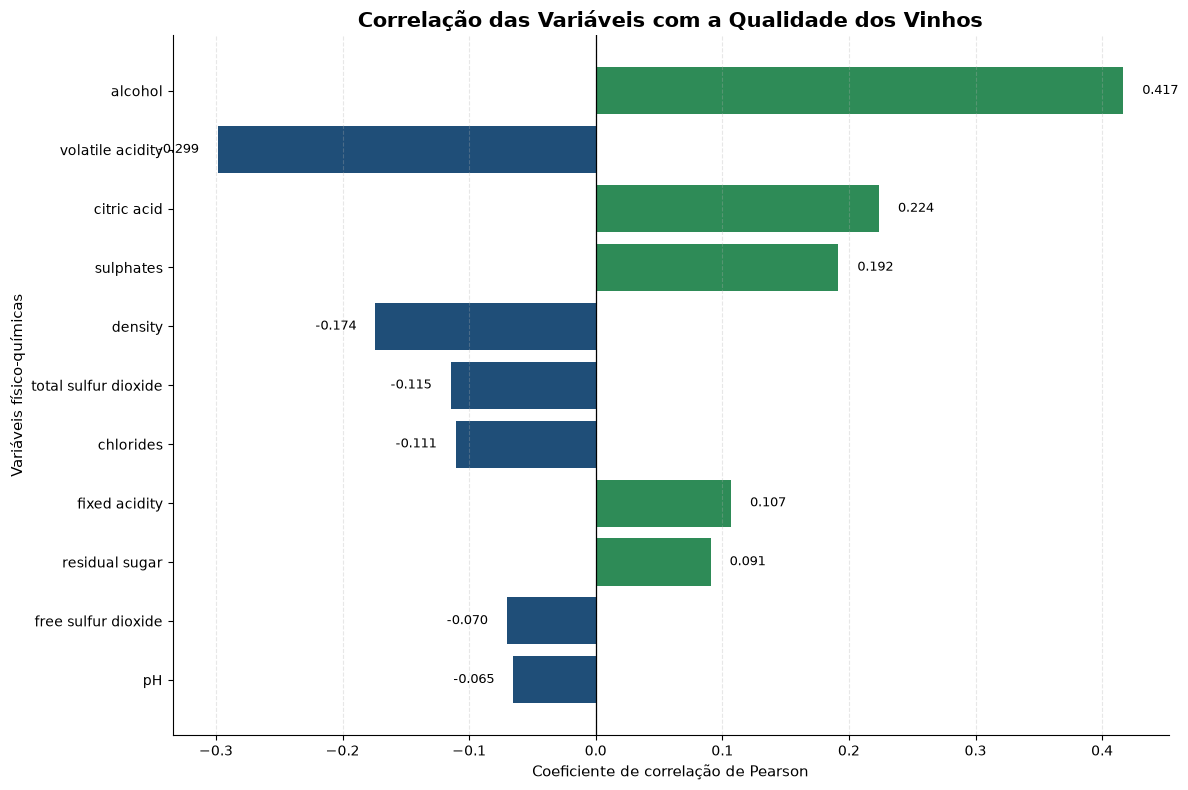

In [15]:
# ============================================================
# 16. GRÁFICO DE CORRELAÇÃO COM QUALITY_CLASS
# ============================================================

# Objetivo:
# Visualizar a correlação das 11 variáveis físico-químicas
# com a variável alvo quality_class.
#
# As variáveis serão organizadas pela intensidade da correlação,
# considerando seus valores absolutos.


# ------------------------------------------------------------
# 16.1 Preparação dos dados
# ------------------------------------------------------------

# Ordena as correlações do menor para o maior valor absoluto.
# Essa organização facilita a leitura no gráfico horizontal.

correlacao_grafico = correlacao_quality.sort_values(
    key=abs,
    ascending=True
)


# ------------------------------------------------------------
# 16.2 Definição das cores
# ------------------------------------------------------------

# Associa azul às correlações negativas e verde às positivas.

cores = [
    "#1F4E78" if valor < 0 else "#2E8B57"
    for valor in correlacao_grafico.values
]


# ------------------------------------------------------------
# 16.3 Criação do gráfico
# ------------------------------------------------------------

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 8))

# Cria as barras horizontais.

barras = ax.barh(
    correlacao_grafico.index,
    correlacao_grafico.values,
    color=cores
)


# ------------------------------------------------------------
# 16.4 Linha de referência
# ------------------------------------------------------------

# A linha vertical em zero separa correlações positivas
# das correlações negativas.

ax.axvline(
    0,
    color="black",
    linewidth=0.9
)


# ------------------------------------------------------------
# 16.5 Exibição dos valores
# ------------------------------------------------------------

# Adiciona o valor numérico ao lado de cada barra.

for barra in barras:

    largura = barra.get_width()

    deslocamento = 0.015 if largura >= 0 else -0.015

    ax.text(
        largura + deslocamento,
        barra.get_y() + barra.get_height() / 2,
        f"{largura:.3f}",
        va="center",
        ha="left" if largura >= 0 else "right",
        fontsize=9
    )


# ------------------------------------------------------------
# 16.6 Personalização do gráfico
# ------------------------------------------------------------

ax.set_title(
    "Correlação das Variáveis com a Qualidade dos Vinhos",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel(
    "Coeficiente de correlação de Pearson",
    fontsize=11
)

ax.set_ylabel(
    "Variáveis físico-químicas",
    fontsize=11
)

# Adiciona linhas de grade horizontais de referência.

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

# Remove as bordas superior e direita para melhorar a apresentação.

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Ajusta o espaçamento e apresenta o gráfico.

plt.tight_layout()

plt.show()

### 16.1 Interpretação do gráfico de correlação com quality_class

O gráfico apresenta as correlações entre as variáveis físico-químicas e a variável alvo `quality_class`, utilizando cores distintas para representar as associações positivas e negativas.

As principais observações foram:

- **Alcohol:** apresentou a maior correlação positiva (0,417), sendo a variável com maior associação linear positiva com a classificação.
- **Volatile acidity:** apresentou a maior correlação negativa (-0,299), indicando uma associação inversa com a classe de qualidade.
- **Citric acid e sulphates:** apresentaram correlações positivas, porém de menor intensidade.
- **Density e total sulfur dioxide:** apresentaram correlações negativas fracas.

De modo geral, os resultados indicam que algumas variáveis apresentam associações mais relevantes com a classificação da qualidade, especialmente alcohol e volatile acidity.

Essa análise é exploratória e não permite concluir, isoladamente, quais variáveis terão maior importância preditiva no modelo.

In [16]:
# ============================================================
# 17. MATRIZ DE CORRELAÇÃO ENTRE AS FEATURES
# ============================================================

# Objetivo:
# Analisar as relações lineares entre as variáveis
# físico-químicas utilizadas pelo modelo.
#
# A análise utiliza somente X_train e não modifica
# os arquivos originais nem os conjuntos de dados.


# ------------------------------------------------------------
# 17.1 Cálculo da matriz de correlação
# ------------------------------------------------------------

# Calcula a correlação de Pearson entre todas as features.
# O método Pearson mede a intensidade e a direção
# das relações lineares entre as variáveis.

matriz_correlacao_features = X_train.corr(method="pearson")


# ------------------------------------------------------------
# 17.2 Exibição da matriz
# ------------------------------------------------------------

# Apresenta os coeficientes com três casas decimais
# para facilitar a leitura e comparação.

print("MATRIZ DE CORRELAÇÃO ENTRE AS FEATURES")
print("-" * 65)

display(matriz_correlacao_features.round(3))

MATRIZ DE CORRELAÇÃO ENTRE AS FEATURES
-----------------------------------------------------------------


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
fixed acidity,1.000,-0.246,0.666,0.129,0.088,-0.154,-0.098,0.691,-0.686,0.157,-0.123
volatile acidity,-0.246,1.000,-0.548,-0.005,0.038,-0.010,0.068,0.020,0.241,-0.273,-0.204
citric acid,0.666,-0.548,1.000,0.162,0.256,-0.047,0.054,0.373,-0.557,0.328,0.074
residual sugar,0.129,-0.005,0.162,1.000,0.038,0.138,0.205,0.319,-0.089,0.005,0.103
chlorides,0.088,0.038,0.256,0.038,1.000,0.012,0.040,0.206,-0.270,0.408,-0.244
free sulfur dioxide,-0.154,-0.010,-0.047,0.138,0.012,1.000,0.660,-0.049,0.050,0.050,-0.060
total sulfur dioxide,-0.098,0.068,0.054,0.205,0.040,0.660,1.000,0.042,-0.097,0.024,-0.195
density,0.691,0.020,0.373,0.319,0.206,-0.049,0.042,1.000,-0.360,0.144,-0.522
pH,-0.686,0.241,-0.557,-0.089,-0.270,0.050,-0.097,-0.360,1.000,-0.192,0.257
sulphates,0.157,-0.273,0.328,0.005,0.408,0.050,0.024,0.144,-0.192,1.000,0.063


### 17.1 Interpretação da matriz de correlação entre as features

A matriz de correlação de Pearson permitiu identificar relações lineares entre as variáveis físico-químicas utilizadas na modelagem.

Foram observadas correlações positivas relevantes entre:

- `fixed acidity` e `density` (0,691);
- `fixed acidity` e `citric acid` (0,666);
- `free sulfur dioxide` e `total sulfur dioxide` (0,660).

Também foram identificadas correlações negativas relevantes entre:

- `fixed acidity` e `pH` (-0,686);
- `citric acid` e `pH` (-0,557);
- `volatile acidity` e `citric acid` (-0,548);
- `density` e `alcohol` (-0,522).

Esses resultados indicam que determinadas variáveis apresentam relações lineares entre si e podem compartilhar informações semelhantes.

Na etapa de modelagem, essas relações merecem atenção devido à possibilidade de multicolinearidade, especialmente em modelos lineares como a regressão logística.

Entretanto, as correlações observadas não justificam, isoladamente, a exclusão de variáveis. Será necessário avaliar seu impacto no desempenho e na estabilidade do modelo.

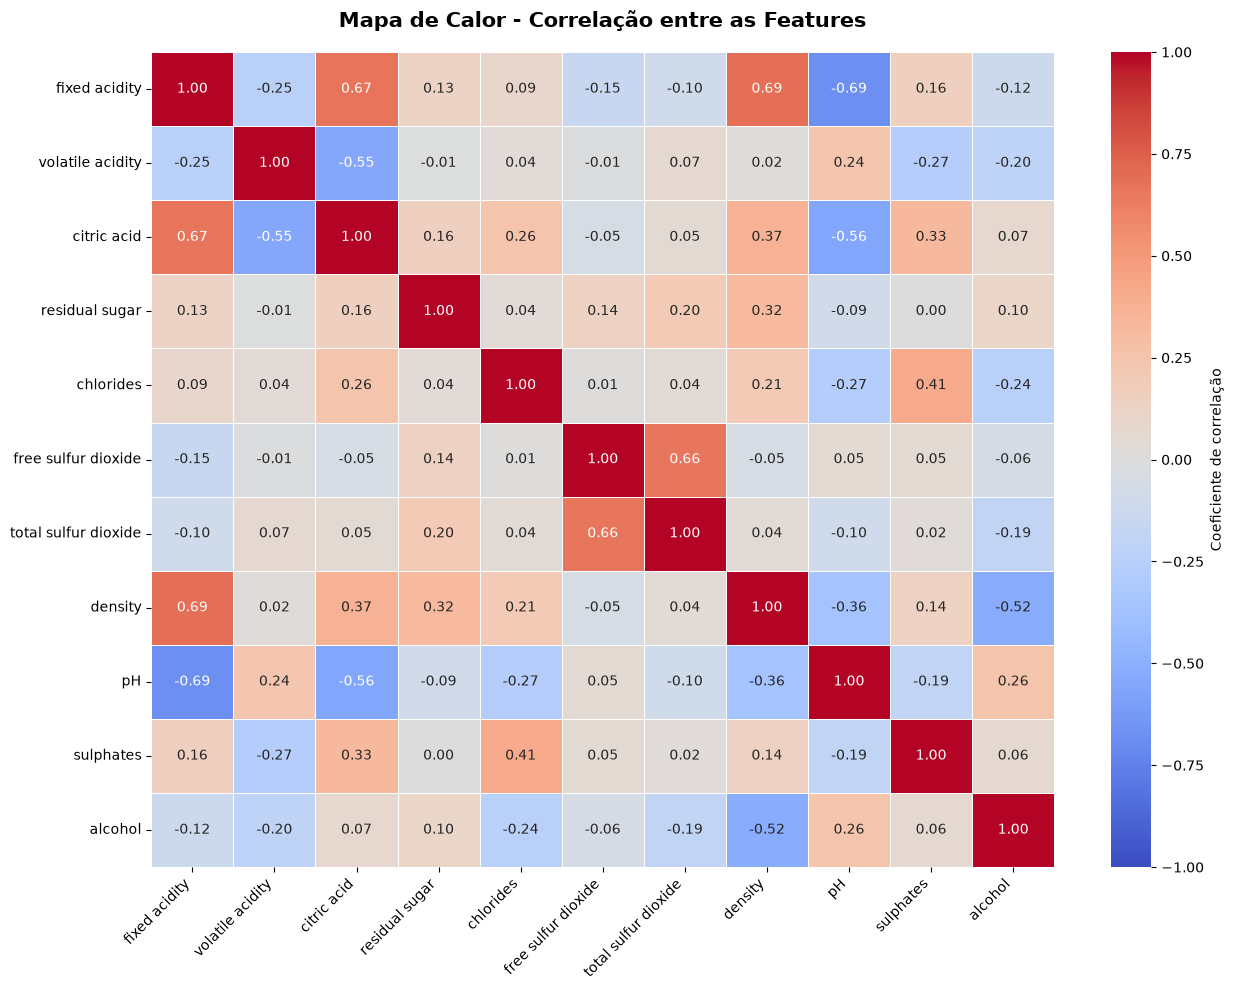

In [17]:
# ============================================================
# 18. MAPA DE CALOR DA MATRIZ DE CORRELAÇÃO
# ============================================================

# Objetivo:
# Representar visualmente as correlações entre as 11 features.
#
# Tons mais próximos de 1 indicam correlação positiva.
# Tons mais próximos de -1 indicam correlação negativa.
# Valores próximos de zero indicam correlação linear fraca.
#
# A visualização utiliza a matriz já calculada anteriormente,
# sem modificar os dados originais.


# ------------------------------------------------------------
# 18.1 Importação da biblioteca de visualização
# ------------------------------------------------------------

import matplotlib.pyplot as plt
import seaborn as sns


# ------------------------------------------------------------
# 18.2 Configuração do tamanho do gráfico
# ------------------------------------------------------------

plt.figure(figsize=(13, 10))


# ------------------------------------------------------------
# 18.3 Construção do mapa de calor
# ------------------------------------------------------------

sns.heatmap(
    matriz_correlacao_features,

    # Exibe os coeficientes dentro de cada quadrado
    annot=True,

    # Apresenta os valores com três casas decimais
    fmt=".2f",

    # Utiliza uma escala divergente para destacar
    # correlações positivas e negativas
    cmap="coolwarm",

    # Define os limites da escala de correlação
    vmin=-1,
    vmax=1,
    center=0,

    # Adiciona uma barra lateral com a escala de cores
    cbar_kws={
        "label": "Coeficiente de correlação"
    },

    # Linhas brancas para separar as células
    linewidths=0.5
)


# ------------------------------------------------------------
# 18.4 Personalização do gráfico
# ------------------------------------------------------------

plt.title(
    "Mapa de Calor - Correlação entre as Features",
    fontsize=15,
    fontweight="bold",
    pad=18
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

# Ajusta o espaçamento para evitar cortes nos nomes
plt.tight_layout()


# ------------------------------------------------------------
# 18.5 Exibição do gráfico
# ------------------------------------------------------------

plt.show()

### 18.1 Interpretação do mapa de calor

O mapa de calor permite visualizar a intensidade e a direção das correlações entre as variáveis físico-químicas do conjunto de treinamento.

As principais relações identificadas foram:

- `fixed acidity` e `density`: correlação positiva de 0,691.
- `fixed acidity` e `citric acid`: correlação positiva de 0,666.
- `free sulfur dioxide` e `total sulfur dioxide`: correlação positiva de 0,660.
- `fixed acidity` e `pH`: correlação negativa de -0,686.
- `citric acid` e `pH`: correlação negativa de -0,557.
- `volatile acidity` e `citric acid`: correlação negativa de -0,548.
- `density` e `alcohol`: correlação negativa de -0,522.

A visualização reforça a existência de relações lineares relevantes entre alguns pares de variáveis.

Essas relações serão consideradas na investigação de possível multicolinearidade, especialmente por se tratar de um modelo de regressão logística.

Não será realizada exclusão automática de variáveis nesta etapa, pois a decisão deverá considerar também o comportamento e o desempenho do modelo.

In [2]:
# ============================================================
# 19.0 INSTALAÇÃO DA BIBLIOTECA STATSMODELS
# ============================================================

# Instala a biblioteca necessária para calcular o VIF
# no mesmo ambiente Python utilizado pelo notebook.

%pip install statsmodels

  Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl.metadata (61 kB)
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
   --- ------------------------------------ 1.0/11.3 MB 2.8 MB/s eta 0:00:04
   ----- ---------------------------------- 1.6/11.3 MB 3.0 MB/s eta 0:00:04
   -------- ------------------------------- 2.4/11.3 MB 3.2 MB/s eta 0:00:03
   ----------- ---------------------------- 3.1/11.3 MB 3.1 MB/s eta 0:00:03
   ------------ --------------------------- 3.7/11.3 MB 3.1 MB/s eta 0:00:03
   --------------- ------------------------ 4.5/11.3 MB 3.1 MB/s eta 0:00:03
   ------------------ --------------------- 5.2/11.3 MB 3.2 MB/s eta 0:00:02
   --------------------- ------------------ 6.0/11.3 MB 3.2 MB/s eta 0:00:02
   ----------------------- ---------------- 6.6/11.3 MB 3.2 MB/s eta 0:00:02
   ------------------------- -------------- 7.3/11.3 MB 3.2 MB/s eta 0:00:02
   ----------------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# ============================================================
# 19. ANÁLISE DE MULTICOLINEARIDADE COM VIF
# ============================================================

# Objetivo:
# Avaliar quanto cada variável explicativa pode ser
# explicada linearmente pelas demais features.
#
# O cálculo utiliza somente X_train.
# Nenhum arquivo original será alterado.


# ------------------------------------------------------------
# 19.1 Importação da função VIF
# ------------------------------------------------------------

from statsmodels.stats.outliers_influence import variance_inflation_factor


# ------------------------------------------------------------
# 19.2 Preparação dos dados
# ------------------------------------------------------------

# Cria uma cópia do conjunto de treinamento para a análise.
# A cópia evita qualquer alteração no X_train original.

dados_vif = X_train.copy()

# Garante que todas as colunas estejam em formato numérico.

dados_vif = dados_vif.astype(float)


# ------------------------------------------------------------
# 19.3 Cálculo do VIF para cada variável
# ------------------------------------------------------------

# Calcula o VIF individualmente para cada feature.
# O índice das colunas é utilizado para identificar
# cada variável analisada.

resultados_vif = pd.DataFrame()

resultados_vif["variavel"] = dados_vif.columns

resultados_vif["VIF"] = [
    variance_inflation_factor(
        dados_vif.values,
        indice
    )
    for indice in range(dados_vif.shape[1])
]


# ------------------------------------------------------------
# 19.4 Organização dos resultados
# ------------------------------------------------------------

# Ordena as variáveis da maior para a menor VIF,
# facilitando a identificação dos maiores valores.

resultados_vif = resultados_vif.sort_values(
    by="VIF",
    ascending=False
).reset_index(drop=True)


# ------------------------------------------------------------
# 19.5 Exibição dos resultados
# ------------------------------------------------------------

print("ANÁLISE DE MULTICOLINEARIDADE - VIF")
print("-" * 55)

display(resultados_vif.round(3))

ANÁLISE DE MULTICOLINEARIDADE - VIF
-------------------------------------------------------


,variavel,VIF
0,fixed acidity,8.046
1,density,6.713
2,pH,3.525
3,alcohol,3.343
4,citric acid,3.288
5,total sulfur dioxide,2.170
6,free sulfur dioxide,1.887
7,volatile acidity,1.793
8,residual sugar,1.723
9,chlorides,1.622


In [4]:
# ============================================================
# 20. RECÁLCULO DO VIF COM CONSTANTE
# ============================================================

# Objetivo:
# Recalcular o VIF incluindo uma constante (intercepto),
# para avaliar a multicolinearidade entre as features
# considerando o modelo com intercepto.


# ------------------------------------------------------------
# 20.1 Importação das bibliotecas
# ------------------------------------------------------------

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant


# ------------------------------------------------------------
# 20.2 Preparação dos dados
# ------------------------------------------------------------

# Cria uma cópia dos dados de treinamento.
# Os arquivos originais permanecem preservados.

dados_vif_constante = X_train.copy().astype(float)


# ------------------------------------------------------------
# 20.3 Inclusão da constante
# ------------------------------------------------------------

# Adiciona uma coluna de constante para representar
# o intercepto do modelo de regressão.

dados_vif_constante = add_constant(
    dados_vif_constante,
    has_constant="add"
)


# ------------------------------------------------------------
# 20.4 Cálculo do VIF
# ------------------------------------------------------------

resultados_vif = pd.DataFrame()

# Exclui a constante da tabela final, pois nosso objetivo
# é avaliar somente as variáveis explicativas.

variaveis = dados_vif_constante.columns.drop("const")

resultados_vif["variavel"] = variaveis

resultados_vif["VIF"] = [
    variance_inflation_factor(
        dados_vif_constante.values,
        dados_vif_constante.columns.get_loc(variavel)
    )
    for variavel in variaveis
]


# ------------------------------------------------------------
# 20.5 Organização e apresentação
# ------------------------------------------------------------

resultados_vif = resultados_vif.sort_values(
    by="VIF",
    ascending=False
).reset_index(drop=True)

print("VIF COM CONSTANTE - ANÁLISE DE MULTICOLINEARIDADE")
print("-" * 65)

display(resultados_vif.round(3))

VIF COM CONSTANTE - ANÁLISE DE MULTICOLINEARIDADE
-----------------------------------------------------------------


,variavel,VIF
0,fixed acidity,8.046
1,density,6.713
2,pH,3.525
3,alcohol,3.343
4,citric acid,3.288
5,total sulfur dioxide,2.170
6,free sulfur dioxide,1.887
7,volatile acidity,1.793
8,residual sugar,1.723
9,chlorides,1.622


In [5]:
# ============================================================
# 21. CONFERÊNCIA DO CÁLCULO DO VIF COM CONSTANTE
# ============================================================

# Verifica se a coluna de constante foi adicionada corretamente
print("Colunas utilizadas no cálculo:")
print(dados_vif_constante.columns.tolist())

# Verifica se a coluna constante contém somente o valor 1
print("\nValores da coluna constante:")
print(dados_vif_constante["const"].unique())

# Exibe os valores de VIF calculados
print("\nResultados do VIF:")
display(resultados_vif.round(6))

Colunas utilizadas no cálculo:
['const', 'fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']

Valores da coluna constante:
[1.]

Resultados do VIF:


,variavel,VIF
0,fixed acidity,8.045638
1,density,6.712572
2,pH,3.525240
3,alcohol,3.343036
4,citric acid,3.287642
5,total sulfur dioxide,2.170021
6,free sulfur dioxide,1.886718
7,volatile acidity,1.793328
8,residual sugar,1.723221
9,chlorides,1.621784


In [6]:
# ============================================================
# 21. VERIFICAÇÃO DA CONSTANTE NO CÁLCULO DO VIF
# ============================================================

# Exibe as colunas utilizadas no cálculo
print("Colunas utilizadas:")
print(dados_vif_constante.columns.tolist())

# Verifica os valores da coluna constante
print("\nValores encontrados na coluna 'const':")
print(dados_vif_constante["const"].unique())

# Confere a posição da constante
print("\nPrimeiras linhas da base utilizada:")
display(dados_vif_constante.head())

Colunas utilizadas:
['const', 'fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']

Valores encontrados na coluna 'const':
[1.]

Primeiras linhas da base utilizada:


,const,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,1.0,7.0,0.42,0.19,2.30,0.071,18.0,36.0,0.99476,3.39,0.56,10.9
1,1.0,9.1,0.29,0.33,2.05,0.063,13.0,27.0,0.99516,3.26,0.84,11.7
2,1.0,7.6,0.30,0.42,2.00,0.052,6.0,24.0,0.99630,3.44,0.82,11.9
3,1.0,11.7,0.28,0.47,1.70,0.054,17.0,32.0,0.99686,3.15,0.67,10.6
4,1.0,7.0,0.49,0.49,5.60,0.060,26.0,121.0,0.99740,3.34,0.76,10.5


In [7]:
# ============================================================
# 22. RECÁLCULO DO VIF COM INTERCEPTO
# ============================================================

# Importa a função utilizada para calcular o VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Importa a função que adiciona a constante
from statsmodels.tools.tools import add_constant

# Cria uma cópia das variáveis explicativas de treinamento
# Os dados originais permanecem preservados
X_vif = X_train.copy().astype(float)

# Adiciona uma coluna constante para representar o intercepto
X_vif = add_constant(X_vif, has_constant="add")

# Calcula o VIF de cada variável explicativa
# A posição zero corresponde à constante; por isso, começamos em 1
vif_intercepto = pd.DataFrame({
    "variavel": X_train.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, indice + 1)
        for indice in range(X_train.shape[1])
    ]
})

# Organiza os resultados do maior para o menor VIF
vif_intercepto = vif_intercepto.sort_values(
    by="VIF",
    ascending=False
).reset_index(drop=True)

# Exibe a tabela com três casas decimais
display(vif_intercepto.round(3))

,variavel,VIF
0,fixed acidity,8.046
1,density,6.713
2,pH,3.525
3,alcohol,3.343
4,citric acid,3.288
5,total sulfur dioxide,2.170
6,free sulfur dioxide,1.887
7,volatile acidity,1.793
8,residual sugar,1.723
9,chlorides,1.622


### Análise de multicolinearidade por meio do VIF

Foi utilizado o Variance Inflation Factor (VIF) para avaliar a existência de multicolinearidade entre as variáveis explicativas do conjunto de treinamento.

Os resultados indicaram que a variável **fixed acidity** apresentou o maior VIF (8,046), seguida por **density** (6,713). Esses valores sugerem possível multicolinearidade elevada, especialmente para fixed acidity, e indicam que essas variáveis merecem atenção durante a modelagem.

As variáveis pH (3,525), alcohol (3,343) e citric acid (3,288) apresentaram valores moderados. As demais variáveis registraram valores inferiores a 3.

Os resultados também são coerentes com a matriz de correlação, que identificou relações relevantes entre algumas dessas variáveis.

Neste momento, nenhuma variável será removida. A multicolinearidade será considerada na interpretação dos coeficientes da regressão logística e na avaliação do desempenho do modelo, preservando inicialmente todas as características disponíveis.

In [8]:

# ============================================================
# 23. ANÁLISE DOS COEFICIENTES DA REGRESSÃO LOGÍSTICA
# ============================================================

# Recupera o classificador treinado dentro da pipeline
classificador = modelo_logistico.named_steps["classificador"]

# Recupera os coeficientes estimados pelo modelo
coeficientes = classificador.coef_[0]

# Cria uma tabela relacionando cada variável ao seu coeficiente
tabela_coeficientes = pd.DataFrame({
    "variavel": X_train.columns,
    "coeficiente": coeficientes
})

# Organiza as variáveis pelo valor absoluto dos coeficientes,
# destacando aquelas com maior magnitude
tabela_coeficientes["magnitude"] = (
    tabela_coeficientes["coeficiente"].abs()
)

tabela_coeficientes = tabela_coeficientes.sort_values(
    by="magnitude",
    ascending=False
).reset_index(drop=True)

# Exibe os coeficientes estimados pelo modelo
display(tabela_coeficientes.round(4))


NameError: name 'modelo_logistico' is not defined

In [9]:
# ============================================================
# 23.1. RECARREGAMENTO DOS DADOS DE TREINAMENTO E TESTE
# ============================================================

# Importa a biblioteca para manipulação dos dados
import pandas as pd

# Define o caminho dos arquivos preparados
caminho_resultados = "../data_priscila/wq/etapa_3/resultados/"

# Carrega as variáveis explicativas de treinamento e teste
X_train = pd.read_csv(caminho_resultados + "X_train.csv")
X_test = pd.read_csv(caminho_resultados + "X_test.csv")

# Carrega as variáveis alvo de treinamento e teste
y_train = pd.read_csv(caminho_resultados + "y_train.csv").squeeze()
y_test = pd.read_csv(caminho_resultados + "y_test.csv").squeeze()

# Confere as dimensões dos conjuntos carregados
print("Dados carregados com sucesso!")
print(f"X_train: {X_train.shape}")
print(f"X_test: {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test: {y_test.shape}")

Dados carregados com sucesso!
X_train: (814, 11)
X_test: (204, 11)
y_train: (814,)
y_test: (204,)


In [12]:
# ============================================================
# 23.2.1. VERIFICAÇÃO DO AMBIENTE PYTHON
# ============================================================

# Importa a biblioteca responsável por identificar o ambiente
import sys

# Exibe o caminho do interpretador Python utilizado pelo notebook
print("Interpretador Python em uso:")
print(sys.executable)

# Exibe a versão do Python
print("\nVersão do Python:")
print(sys.version)

Interpretador Python em uso:
c:\Users\prisc\AppData\Local\Python\pythoncore-3.14-64\python.exe

Versão do Python:
3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)]


In [1]:
import sys
print(sys.executable)

c:\Users\prisc\Desktop\Fase 2\.venv\Scripts\python.exe


In [2]:
# ============================================================
# 23.2.2. VERIFICAÇÃO DAS BIBLIOTECAS DO MODELO
# ============================================================

# Verifica se o scikit-learn está disponível no ambiente
import sklearn

# Exibe a versão instalada
print("Scikit-learn instalado com sucesso!")
print("Versão:", sklearn.__version__)

Scikit-learn instalado com sucesso!
Versão: 1.9.1


In [4]:
# ============================================================
# 23.2. RECARREGAMENTO DOS DADOS DE TREINAMENTO E TESTE
# ============================================================

# Importa a biblioteca para manipulação dos dados
import pandas as pd

# Define o caminho dos arquivos preparados
caminho_resultados = "../data_priscila/wq/etapa_3/resultados/"

# Carrega as variáveis explicativas de treinamento e teste
X_train = pd.read_csv(caminho_resultados + "X_train.csv")
X_test = pd.read_csv(caminho_resultados + "X_test.csv")

# Carrega as variáveis alvo de treinamento e teste
y_train = pd.read_csv(caminho_resultados + "y_train.csv").squeeze()
y_test = pd.read_csv(caminho_resultados + "y_test.csv").squeeze()

# Confere se os dados foram carregados corretamente
print("Dados carregados com sucesso!")
print(f"X_train: {X_train.shape}")
print(f"X_test: {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test: {y_test.shape}")

Dados carregados com sucesso!
X_train: (814, 11)
X_test: (204, 11)
y_train: (814,)
y_test: (204,)


In [5]:
# ============================================================
# 23.3. RECONSTRUÇÃO DA PIPELINE DE REGRESSÃO LOGÍSTICA
# ============================================================

# Importa as ferramentas necessárias para o modelo
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Cria novamente a pipeline de regressão logística
modelo_logistico = Pipeline(steps=[
    ("escalonamento", RobustScaler()),
    ("classificador", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Treina o modelo utilizando somente os dados de treinamento
modelo_logistico.fit(X_train, y_train)

# Confirma a conclusão do treinamento
print("Modelo de regressão logística reconstruído e treinado!")

Modelo de regressão logística reconstruído e treinado!


In [6]:
# ============================================================
# 23.4. EXTRAÇÃO E ORGANIZAÇÃO DOS COEFICIENTES
# ============================================================

# Recupera o classificador treinado dentro da pipeline
classificador = modelo_logistico.named_steps["classificador"]

# Extrai os coeficientes estimados para a classe 1
coeficientes = classificador.coef_[0]

# Cria uma tabela associando cada variável ao seu coeficiente
tabela_coeficientes = pd.DataFrame({
    "variavel": X_train.columns,
    "coeficiente": coeficientes
})

# Calcula o valor absoluto para avaliar a magnitude dos coeficientes
tabela_coeficientes["magnitude"] = (
    tabela_coeficientes["coeficiente"].abs()
)

# Ordena as variáveis da maior para a menor magnitude
tabela_coeficientes = tabela_coeficientes.sort_values(
    by="magnitude",
    ascending=False
).reset_index(drop=True)

# Exibe os resultados com quatro casas decimais
display(tabela_coeficientes.round(4))

,variavel,coeficiente,magnitude
0,alcohol,1.1676,1.1676
1,density,-0.8304,0.8304
2,volatile acidity,-0.7711,0.7711
3,fixed acidity,0.7144,0.7144
4,sulphates,0.6698,0.6698
5,total sulfur dioxide,-0.4815,0.4815
6,citric acid,0.2529,0.2529
7,residual sugar,0.2503,0.2503
8,chlorides,-0.1909,0.1909
9,pH,-0.0688,0.0688


### Interpretação dos coeficientes da regressão logística

A análise dos coeficientes permitiu identificar as variáveis que apresentam maior associação com a classificação dos vinhos na classe 1, correspondente à qualidade igual ou superior a 7.

A variável **alcohol** apresentou o maior coeficiente positivo (1,1676), indicando associação positiva com a probabilidade de classificação nessa categoria. Também se destacaram fixed acidity (0,7144) e sulphates (0,6698).

Entre as associações negativas, destacaram-se density (-0,8304) e volatile acidity (-0,7711), seguidas por total sulfur dioxide (-0,4815).

A variável free sulfur dioxide apresentou coeficiente próximo de zero (0,0362), sugerindo uma contribuição linear pequena para a decisão do modelo.

Esses resultados representam associações estimadas pelo modelo, considerando simultaneamente as demais variáveis explicativas. Portanto, não devem ser interpretados como relações de causa e efeito.

Também é importante considerar os resultados da análise de multicolinearidade, especialmente para fixed acidity e density, pois a correlação entre variáveis pode influenciar a estabilidade e a interpretação dos coeficientes.

Conclui-se que alcohol, density, volatile acidity, fixed acidity e sulphates se destacaram entre as variáveis com maior magnitude de coeficientes na regressão logística.

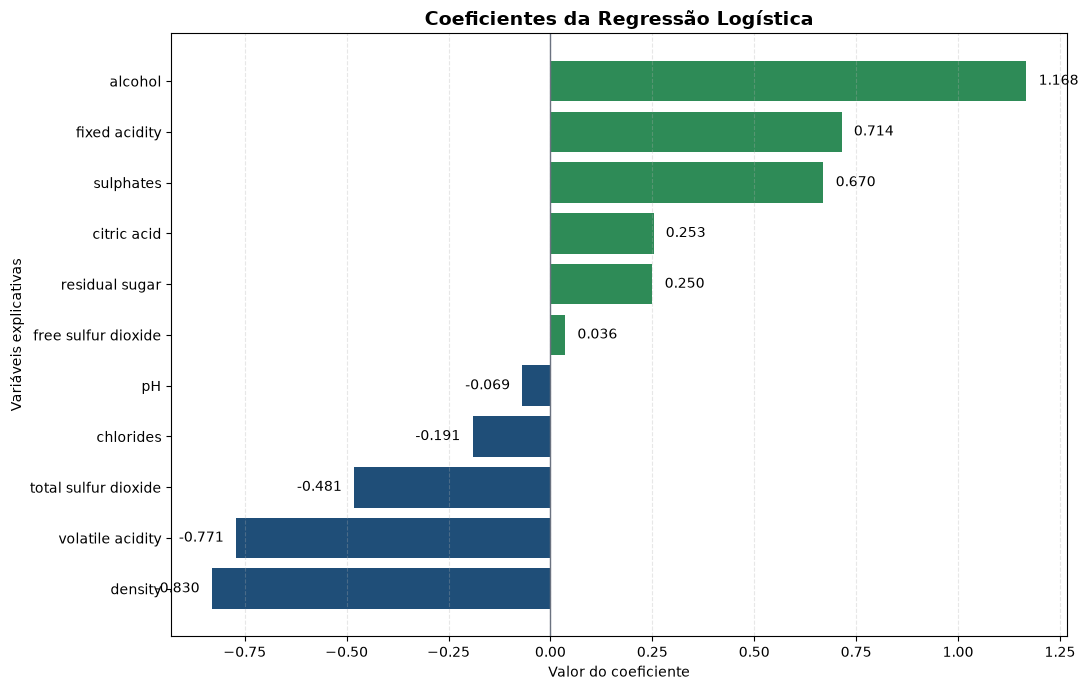

In [7]:
# ============================================================
# 23.5. VISUALIZAÇÃO DOS COEFICIENTES DA REGRESSÃO LOGÍSTICA
# ============================================================

# Importa a biblioteca para criação dos gráficos
import matplotlib.pyplot as plt

# Cria uma cópia da tabela para preservar os resultados originais
dados_grafico = tabela_coeficientes.copy()

# Organiza as variáveis pelo valor dos coeficientes
dados_grafico = dados_grafico.sort_values(
    by="coeficiente",
    ascending=True
)

# Define uma cor para cada direção do coeficiente
cores = [
    "#1F4E78" if valor < 0 else "#2E8B57"
    for valor in dados_grafico["coeficiente"]
]

# Define o tamanho da figura
plt.figure(figsize=(11, 7))

# Cria o gráfico de barras horizontais
barras = plt.barh(
    dados_grafico["variavel"],
    dados_grafico["coeficiente"],
    color=cores
)

# Adiciona uma linha vertical na posição zero
plt.axvline(
    x=0,
    color="#6B7280",
    linewidth=1
)

# Adiciona os valores dos coeficientes nas barras
for barra in barras:

    # Recupera o valor da barra
    valor = barra.get_width()

    # Posiciona o rótulo conforme o sinal do coeficiente
    deslocamento = 0.03 if valor >= 0 else -0.03

    plt.text(
        valor + deslocamento,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.3f}",
        va="center",
        ha="left" if valor >= 0 else "right"
    )

# Define o título e os rótulos dos eixos
plt.title(
    "Coeficientes da Regressão Logística",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Valor do coeficiente")
plt.ylabel("Variáveis explicativas")

# Adiciona uma grade discreta para facilitar a leitura
plt.grid(axis="x", linestyle="--", alpha=0.3)

# Ajusta o espaçamento da figura
plt.tight_layout()

# Exibe o gráfico
plt.show()

### Visualização dos coeficientes da regressão logística

O gráfico apresenta os coeficientes estimados pela regressão logística, permitindo comparar a direção e a magnitude da associação de cada variável com a classificação dos vinhos.

As barras verdes representam coeficientes positivos, associados ao aumento da probabilidade estimada de classificação na classe 1. As barras azuis representam coeficientes negativos, associados à redução dessa probabilidade.

Observou-se que alcohol apresentou o maior coeficiente positivo, enquanto density apresentou o maior coeficiente negativo em magnitude. Também se destacaram volatile acidity, fixed acidity e sulphates.

A visualização complementa a análise da tabela de coeficientes, facilitando a identificação das variáveis com maior magnitude na decisão do modelo.

In [8]:

# ============================================================
# 24.1. OBTENÇÃO DAS PROBABILIDADES DE CLASSIFICAÇÃO
# ============================================================

# Calcula as probabilidades previstas para cada classe
probabilidades = modelo_logistico.predict_proba(X_test)

# Seleciona as probabilidades referentes à classe 1
# Classe 1 = qualidade igual ou superior a 7
probabilidade_classe_1 = probabilidades[:, 1]

# Exibe as primeiras probabilidades calculadas
print("Primeiras probabilidades previstas para a classe 1:")
print(probabilidade_classe_1[:10])


Primeiras probabilidades previstas para a classe 1:
[0.1349533  0.48315887 0.00385583 0.0421174  0.00437809 0.0034689
 0.1050398  0.00479305 0.0580483  0.04861427]


In [9]:

# ============================================================
# 24.2. COMPARAÇÃO DE DIFERENTES THRESHOLDS
# ============================================================

# Importa as métricas utilizadas na avaliação
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

# Define os diferentes limiares que serão avaliados
limiares = [0.30, 0.40, 0.50, 0.60, 0.70]

# Cria uma lista para armazenar os resultados
resultados_threshold = []

# Avalia o modelo utilizando cada limiar
for limiar in limiares:

    # Converte as probabilidades em classes previstas
    # Probabilidade igual ou superior ao limiar = classe 1
    previsoes = (
        probabilidade_classe_1 >= limiar
    ).astype(int)

    # Calcula as métricas de avaliação
    resultados_threshold.append({
        "threshold": limiar,
        "acuracia": accuracy_score(y_test, previsoes),
        "precisao": precision_score(
            y_test, previsoes, zero_division=0
        ),
        "recall": recall_score(
            y_test, previsoes, zero_division=0
        ),
        "f1_score": f1_score(
            y_test, previsoes, zero_division=0
        )
    })

# Organiza os resultados em uma tabela
tabela_threshold = pd.DataFrame(resultados_threshold)

# Exibe a comparação dos resultados
display(tabela_threshold.round(4))


,threshold,acuracia,precisao,recall,f1_score
0,0.3,0.8529,0.4545,0.5556,0.5000
1,0.4,0.8824,0.5556,0.5556,0.5556
2,0.5,0.8971,0.6500,0.4815,0.5532
3,0.6,0.8627,0.4615,0.2222,0.3000
4,0.7,0.8578,0.2500,0.0370,0.0645



### Análise da influência do threshold na classificação

Foi realizada uma comparação entre diferentes limiares de classificação (thresholds), com o objetivo de avaliar seus efeitos sobre o desempenho da regressão logística na identificação de vinhos com qualidade igual ou superior a 7.

Os resultados demonstraram que a redução do threshold de 0,50 para 0,40 aumentou o recall de 48,15% para 55,56%, mantendo também uma precisão de 55,56%. Esse limiar apresentou o maior F1-score entre os valores avaliados (0,5556).

O threshold de 0,50 apresentou a maior acurácia (89,71%) e a maior precisão (65%), mas obteve recall inferior (48,15%). Isso demonstra que uma acurácia mais elevada não significa necessariamente uma melhor identificação dos vinhos da classe minoritária.

Já os thresholds de 0,60 e 0,70 apresentaram reduções expressivas no recall, indicando que limiares mais elevados dificultaram a identificação dos vinhos pertencentes à classe 1.

Assim, entre os limiares avaliados, o valor de 0,40 apresentou o melhor equilíbrio entre precisão e recall, considerando o F1-score. Entretanto, essa análise é exploratória, pois os limiares foram comparados no conjunto de teste. A escolha definitiva deverá ser realizada com dados de validação, mantendo o conjunto de teste reservado para a avaliação final.


In [10]:
# ============================================================
# 23.2. RECARREGAMENTO DOS DADOS DE TREINAMENTO E TESTE
# ============================================================

# Importa a biblioteca para manipulação dos dados
import pandas as pd

# Define o caminho dos arquivos preparados
caminho_resultados = "../data_priscila/wq/etapa_3/resultados/"

# Carrega as variáveis explicativas de treinamento e teste
X_train = pd.read_csv(caminho_resultados + "X_train.csv")
X_test = pd.read_csv(caminho_resultados + "X_test.csv")

# Carrega as variáveis alvo de treinamento e teste
y_train = pd.read_csv(caminho_resultados + "y_train.csv").squeeze()
y_test = pd.read_csv(caminho_resultados + "y_test.csv").squeeze()

# Confere se os dados foram carregados corretamente
print("Dados carregados com sucesso!")
print(f"X_train: {X_train.shape}")
print(f"X_test: {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test: {y_test.shape}")

Dados carregados com sucesso!
X_train: (814, 11)
X_test: (204, 11)
y_train: (814,)
y_test: (204,)


In [12]:

# ============================================================
# 25.1. DIVISÃO DOS DADOS DE TREINAMENTO E VALIDAÇÃO
# ============================================================

from sklearn.model_selection import train_test_split

# Divide os dados de treinamento em subtreino e validação
X_subtreino, X_validacao, y_subtreino, y_validacao = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Exibe os tamanhos dos conjuntos
print("Subtreino:", X_subtreino.shape)
print("Validação:", X_validacao.shape)

# Exibe a quantidade de registros de cada classe
print("\nClasses no conjunto de validação:")
print(y_validacao.value_counts().sort_index())


Subtreino: (651, 11)
Validação: (163, 11)

Classes no conjunto de validação:
quality_class
0    141
1     22
Name: count, dtype: int64


In [13]:

# ============================================================
# 25.2. TREINAMENTO DO MODELO COM O SUBTREINO
# ============================================================

# Importa as bibliotecas necessárias
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Cria um novo pipeline de regressão logística
# O escalonamento será ajustado somente com os dados do subtreino
modelo_validacao = Pipeline(steps=[
    ("escalonamento", RobustScaler()),
    ("classificador", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Treina o modelo com os dados do subtreino
modelo_validacao.fit(X_subtreino, y_subtreino)

# Confirma a conclusão do treinamento
print("Modelo de validação treinado com sucesso!")


Modelo de validação treinado com sucesso!


In [14]:

# ============================================================
# 25.3. CÁLCULO DAS PROBABILIDADES NO CONJUNTO DE VALIDAÇÃO
# ============================================================

# Calcula as probabilidades previstas pelo modelo
probabilidades_validacao = modelo_validacao.predict_proba(X_validacao)

# Seleciona as probabilidades referentes à classe 1
# Classe 1 = qualidade igual ou superior a 7
probabilidade_validacao_classe_1 = probabilidades_validacao[:, 1]

# Exibe as dez primeiras probabilidades
print("Primeiras probabilidades previstas para a classe 1:")
print(probabilidade_validacao_classe_1[:10])

# Exibe a quantidade de probabilidades calculadas
print("\nTotal de probabilidades calculadas:")
print(len(probabilidade_validacao_classe_1))


Primeiras probabilidades previstas para a classe 1:
[0.00405073 0.40129764 0.10505983 0.17932652 0.00441907 0.00359519
 0.31790401 0.4630495  0.19936505 0.00401983]

Total de probabilidades calculadas:
163


In [15]:

# ============================================================
# 25.4. COMPARAÇÃO DOS THRESHOLDS NA VALIDAÇÃO
# ============================================================

# Importa as métricas de avaliação
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Define os thresholds que serão comparados
limiares_validacao = [0.30, 0.40, 0.50, 0.60, 0.70]

# Cria uma lista para armazenar os resultados
resultados_validacao = []

# Avalia o modelo para cada threshold
for limiar in limiares_validacao:

    # Classifica como classe 1 quando a probabilidade
    # prevista for igual ou superior ao threshold
    previsoes_validacao = (
        probabilidade_validacao_classe_1 >= limiar
    ).astype(int)

    # Calcula e armazena as métricas de avaliação
    resultados_validacao.append({
        "threshold": limiar,
        "acuracia": accuracy_score(
            y_validacao, previsoes_validacao
        ),
        "precisao": precision_score(
            y_validacao, previsoes_validacao,
            zero_division=0
        ),
        "recall": recall_score(
            y_validacao, previsoes_validacao,
            zero_division=0
        ),
        "f1_score": f1_score(
            y_validacao, previsoes_validacao,
            zero_division=0
        )
    })

# Organiza os resultados em uma tabela
tabela_validacao = pd.DataFrame(resultados_validacao)

# Exibe a comparação com quatro casas decimais
display(tabela_validacao.round(4))


,threshold,acuracia,precisao,recall,f1_score
0,0.3,0.8650,0.5000,0.5000,0.5000
1,0.4,0.8834,0.6000,0.4091,0.4865
2,0.5,0.8957,0.7778,0.3182,0.4516
3,0.6,0.9018,1.0000,0.2727,0.4286
4,0.7,0.8773,1.0000,0.0909,0.1667


In [16]:

# ============================================================
# 26.1. TREINAMENTO DO MODELO FINAL
# ============================================================

# Cria um novo pipeline de regressão logística
# com escalonamento e classificação
modelo_final = Pipeline(steps=[
    ("escalonamento", RobustScaler()),
    ("classificador", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Treina o modelo utilizando todos os dados de treinamento
# O conjunto de teste permanece separado
modelo_final.fit(X_train, y_train)

# Confirma a conclusão do treinamento
print("Modelo final treinado com sucesso!")


Modelo final treinado com sucesso!


In [17]:

# ============================================================
# 26.2. AVALIAÇÃO FINAL COM THRESHOLD 0.30
# ============================================================

# Importa as métricas de avaliação
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Define o threshold selecionado na validação
threshold_final = 0.30

# Calcula as probabilidades previstas para o conjunto de teste
probabilidades_teste = modelo_final.predict_proba(X_test)

# Seleciona as probabilidades da classe 1
probabilidade_teste_classe_1 = probabilidades_teste[:, 1]

# Converte as probabilidades em classes previstas
previsoes_finais = (
    probabilidade_teste_classe_1 >= threshold_final
).astype(int)

# Calcula as métricas de avaliação
acuracia_final = accuracy_score(y_test, previsoes_finais)
precisao_final = precision_score(
    y_test, previsoes_finais, zero_division=0
)
recall_final = recall_score(
    y_test, previsoes_finais, zero_division=0
)
f1_final = f1_score(
    y_test, previsoes_finais, zero_division=0
)

# Apresenta os resultados
print("RESULTADOS FINAIS DO MODELO")
print("-----------------------------------")
print(f"Threshold utilizado: {threshold_final:.2f}")
print(f"Acurácia:  {acuracia_final:.4f}")
print(f"Precisão:  {precisao_final:.4f}")
print(f"Recall:    {recall_final:.4f}")
print(f"F1-score:  {f1_final:.4f}")

# Apresenta o relatório detalhado por classe
print("\nRELATÓRIO DE CLASSIFICAÇÃO")
print(classification_report(
    y_test,
    previsoes_finais,
    target_names=[
        "Qualidade abaixo de 7",
        "Qualidade igual ou acima de 7"
    ],
    zero_division=0
))


RESULTADOS FINAIS DO MODELO
-----------------------------------
Threshold utilizado: 0.30
Acurácia:  0.8529
Precisão:  0.4545
Recall:    0.5556
F1-score:  0.5000

RELATÓRIO DE CLASSIFICAÇÃO
                               precision    recall  f1-score   support

        Qualidade abaixo de 7       0.93      0.90      0.91       177
Qualidade igual ou acima de 7       0.45      0.56      0.50        27

                     accuracy                           0.85       204
                    macro avg       0.69      0.73      0.71       204
                 weighted avg       0.87      0.85      0.86       204




### Avaliação final do modelo com threshold ajustado

Após a seleção do threshold 0,30 com base nos resultados do conjunto de validação, o modelo foi novamente treinado utilizando todos os 814 registros do conjunto de treinamento e avaliado no conjunto de teste, composto por 204 registros.

O modelo apresentou acurácia de 85,29%, precisão de 45,45%, recall de 55,56% e F1-score de 50% para a classe de qualidade igual ou superior a 7.

Em comparação com o threshold padrão de 0,50, observou-se um aumento do recall, de 48,15% para 55,56%. Entretanto, houve redução da precisão, de 65% para 45,45%, e da acurácia, de 89,71% para 85,29%.

O F1-score também apresentou redução, passando de 55,32% para 50%. Portanto, apesar de o threshold 0,30 ter favorecido a identificação da classe minoritária, não apresentou melhoria no equilíbrio entre precisão e recall quando aplicado ao conjunto de teste.

Os resultados evidenciam a influência do limiar de classificação sobre o comportamento da regressão logística e reforçam a importância de avaliar diferentes métricas, especialmente em bases de dados desbalanceadas.


Matriz de confusão:
[[159  18]
 [ 12  15]]


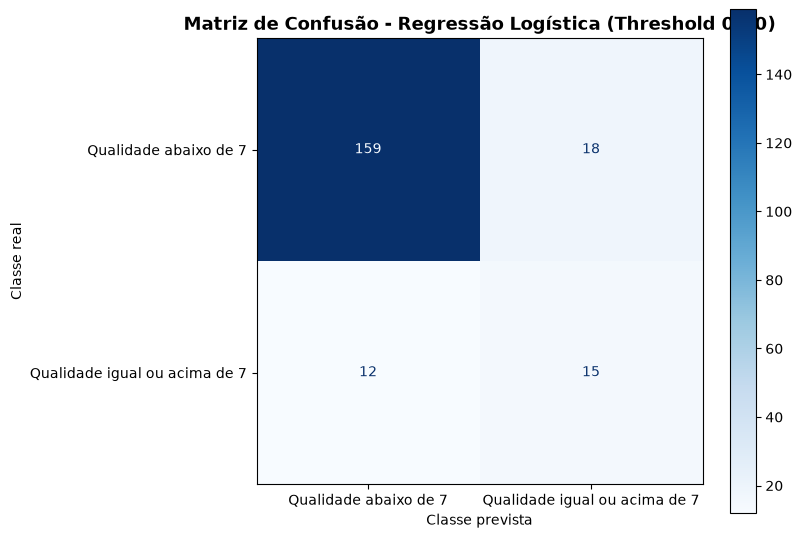

In [19]:

# ============================================================
# 26.3. MATRIZ DE CONFUSÃO DO MODELO FINAL
# Threshold: 0.30
# ============================================================

# Importa as bibliotecas necessárias
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calcula a matriz de confusão
matriz_final = confusion_matrix(
    y_test,
    previsoes_finais
)

# Exibe os valores numéricos da matriz
print("Matriz de confusão:")
print(matriz_final)

# Cria a visualização da matriz
visualizacao = ConfusionMatrixDisplay(
    confusion_matrix=matriz_final,
    display_labels=[
        "Qualidade abaixo de 7",
        "Qualidade igual ou acima de 7"
    ]
)

# Configura e apresenta o gráfico
fig, ax = plt.subplots(figsize=(8, 6))

visualizacao.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title(
    "Matriz de Confusão - Regressão Logística (Threshold 0.30)",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Classe prevista")
plt.ylabel("Classe real")

plt.tight_layout()
plt.show()



### Análise da matriz de confusão do modelo final

A matriz de confusão do modelo com threshold 0,30 apresentou 159 verdadeiros negativos, 18 falsos positivos, 12 falsos negativos e 15 verdadeiros positivos.

Em comparação com o modelo original, que utilizava threshold 0,50, houve aumento de 13 para 15 verdadeiros positivos e redução de 14 para 12 falsos negativos. Isso demonstra uma pequena melhora na identificação dos vinhos pertencentes à classe de qualidade igual ou superior a 7.

Entretanto, os falsos positivos aumentaram de 7 para 18, elevando o total de erros de classificação de 21 para 30.

Dessa forma, a redução do threshold favoreceu a identificação da classe minoritária, mas aumentou a quantidade de classificações incorretas na classe majoritária. A escolha do limiar envolve, portanto, um compromisso entre a identificação dos vinhos de maior qualidade e a precisão geral das previsões.



### Síntese e conclusão da regressão logística

A regressão logística foi utilizada como primeiro algoritmo de classificação para identificar vinhos com qualidade abaixo de 7 e vinhos com qualidade igual ou superior a 7.

O modelo inicial, utilizando threshold de 0,50, apresentou acurácia de 89,71% e F1-score de 55,32% para a classe minoritária. Apesar da boa acurácia geral, o recall de 48,15% demonstrou que o algoritmo apresentava dificuldade para identificar os vinhos de qualidade igual ou superior a 7.

A análise das variáveis explicativas destacou principalmente alcohol, density, volatile acidity, fixed acidity e sulphates, considerando a magnitude dos coeficientes estimados pelo modelo. Essas variáveis apresentaram associações relevantes com as previsões, embora a presença de correlação entre algumas features exija cautela na interpretação individual dos resultados.

Também foi investigada a influência do threshold. O limiar de 0,30 foi selecionado com base no maior F1-score observado no conjunto de validação. Na avaliação final, esse ajuste elevou o recall de 48,15% para 55,56%, mas reduziu a precisão e o F1-score.

Dessa forma, conclui-se que a regressão logística apresentou capacidade de classificação, mas demonstrou limitações na identificação da classe minoritária. Os resultados indicam a necessidade de investigar outros algoritmos e estratégias de modelagem, buscando melhorar o equilíbrio entre as métricas de avaliação.

A regressão logística será mantida como referência para comparação com os próximos modelos de classificação.
